# 🎛️ KTÜ EEM — Kontrol ve Sürücü Sistemleri Lab II
## D3: Frekans Uzayında Kararlılık Analizi

**Karadeniz Teknik Üniversitesi | Elektrik-Elektronik Mühendisliği**

---

Bu notebook, D3 deneyinin tüm teorik arka planını, matematiksel türetimlerini ve Python simülasyonlarını içermektedir.

**İçerik:**
1. Temel Kavramlar (Örnekleme, Transfer Fonksiyonu, PID)
2. Deney 1 — İkinci Derece Sistem Analizi
3. Deney 2 — İnsansız Denizaltı Sistemi (Nyquist, Bode, Root Locus)
4. Soru 6 — Routh-Hurwitz Kararlılık Analizi
5. Sonuçlar ve Yorumlar


www.feyyazatacagirliğim.org## 📦 Gerekli Kütüphaneler

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import control
from IPython.display import display, Math, Markdown
import warnings
warnings.filterwarnings('ignore')

# Jupyter inline plot ayarı
%matplotlib inline
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
})
print("✓ Kütüphaneler yüklendi.")
print(f"  python-control version: {control.__version__}")


✓ Kütüphaneler yüklendi.
  python-control version: 0.10.2


---
## 1️⃣ Hazırlık Soruları

### Soru 1 — Örnekleme Kavramları

#### Örnekleme Frekansı $(f_s)$

Bir saniyede alınan örnek sayısıdır. Birimi Hz (Hertz)'dir.

$$f_s = \frac{1}{T_s} \quad [\text{Hz}]$$

**Nyquist-Shannon Örnekleme Teoremi:**

$$\boxed{f_s \geq 2 \cdot f_{\max}}$$

$f_{\max}$: işarette bulunan en yüksek frekans bileşeni.

#### Örnekleme Adımı $(T_s)$

Ardışık iki örnek arasındaki zaman farkıdır:

$$T_s = \frac{1}{f_s} \quad [\text{s}]$$

#### Örnekleme Oranı

$f_s$ ile eş anlamlıdır; bazen boyutsuz oran olarak da ifade edilir:

$$\text{Örnekleme Oranı} = \frac{f_s}{f_{\text{sinyal}}}$$

> **Pratik not:** Kontrol sistemlerinde $f_s$ en az 10–20× bant genişliği olmalıdır.


### Soru 2 — Transfer Fonksiyonu Türetimi

Verilen diferansiyel denklem:

$$\frac{dx}{dt} = -ax + bu$$

**Adım 1: Laplace dönüşümü** (sıfır başlangıç koşulları, $x(0)=0$):

$$\mathcal{L}\left\{\frac{dx}{dt}\right\} = sX(s) - x(0) = sX(s)$$

$$\mathcal{L}\{-ax + bu\} = -aX(s) + bU(s)$$

**Adım 2: Denklem:**

$$sX(s) = -aX(s) + bU(s)$$

$$(s + a)X(s) = bU(s)$$

**Adım 3: Transfer fonksiyonu:**

$$\boxed{G(s) = \frac{X(s)}{U(s)} = \frac{b}{s + a}}$$

- **Zaman sabiti:** $\tau = \dfrac{1}{a}$  
- **DC kazanç:** $K_{DC} = \dfrac{b}{a}$  
- **Kutup:** $s = -a$ (kararlılık için $a > 0$ olmalı)

#### Blok Diyagram

```
U(s) ──►[ b/(s+a) ]──► X(s)
```

#### PID ile Kapalı Çevrim

$$C(s) = K_p + \frac{K_i}{s} + K_d s = \frac{K_d s^2 + K_p s + K_i}{s}$$

```
R(s) ──►[+]──►[ PID(s) ]──►[ b/(s+a) ]──► X(s)
         ▲─────────────────────────────────────┘
                    (Geri Besleme = -1)
```

Kapalı çevrim transfer fonksiyonu:

$$T(s) = \frac{G(s)C(s)}{1 + G(s)C(s)} = \frac{b \cdot C(s)}{s + a + b \cdot C(s)}$$


### Soru 4 — Nyquist, Bode ve Root Locus

#### Nyquist Diyagramı

Açık çevrim $G(j\omega)$'yı $\omega: -\infty \to +\infty$ için kompleks düzlemde çizer.

**Nyquist Kararlılık Kriteri:**

$$\boxed{Z = N + P}$$

| Sembol | Anlam |
|--------|-------|
| $Z$ | Kapalı çevrim — sağ yarı düzlem kutup sayısı |
| $N$ | $(-1,\,0)$ noktasının saat yönünde sarılma sayısı |
| $P$ | Açık çevrim — sağ yarı düzlem kutup sayısı |

**Kararlılık koşulu:** $Z = 0 \Rightarrow N = -P$

#### Bode Diyagramı

İki alt grafik: **kazanç** $|G(j\omega)|_{dB}$ ve **faz** $\angle G(j\omega)$ vs log-frekans.

$$|G(j\omega)|_{dB} = 20 \log_{10}|G(j\omega)|$$

**Kararlılık Marjinleri:**

$$\text{Kazanç Marjini (GM)} = -20\log_{10}|G(j\omega_{pc})| \quad \text{(faz geçiş frekansında)}$$

$$\text{Faz Marjini (PM)} = 180° + \angle G(j\omega_{gc}) \quad \text{(kazanç geçiş frekansında)}$$

Kararlılık: $GM > 0\,\text{dB}$ **ve** $PM > 0°$

#### Root Locus (Kök Yer Eğrisi)

$K$ kazancı $0 \to \infty$ değişirken kapalı çevrim kutuplarının $s$-düzlemindeki yolunu gösterir.

$$1 + K \cdot G(s) = 0 \implies \text{kapalı çevrim kutupları}$$

- Kutuplar **sol yarı düzlemde** → kararlı  
- Kutuplar **sanal ekseni geçerse** → kritik kararlılık (sürekli salınım)  
- Kutuplar **sağ yarı düzlemde** → kararsız


### Soru 5 — 4. Derece Transfer Fonksiyonu Örneği

**Kararlı örnek** (tüm kutuplar sol yarı düzlemde):

$$G_1(s) = \frac{5(s+2)}{(s+1)(s+3)(s^2 + 2s + 5)}$$

Kutuplar: $s_{1,2} = -1,\,-3$ ve $s_{3,4} = -1 \pm 2j$ → hepsi $\text{Re}(s) < 0$ ✅

**Kararsız örnek** (sağ yarı düzlem kutbu var):

$$G_2(s) = \frac{10}{(s-1)(s+2)(s^2+s+1)}$$

$s_1 = +1 > 0$ → kararsız ❌


---
## 2️⃣ Deney 1 — İkinci Derece Sistem Analizi

### Teorik Arka Plan

Standart ikinci derece sistem:

$$\boxed{G(s) = \frac{\omega_n^2}{s^2 + 2\zeta\omega_n s + \omega_n^2}}$$

| Parametre | Sembol | Etki |
|-----------|--------|------|
| Doğal frekans | $\omega_n$ | Sistemin hız ölçeğini belirler |
| Sönüm oranı | $\zeta$ | Salınım davranışını belirler |
| Sönümlü frekans | $\omega_d = \omega_n\sqrt{1-\zeta^2}$ | Gerçek salınım frekansı |

#### Kutupların konumu

$$s_{1,2} = -\zeta\omega_n \pm j\omega_n\sqrt{1-\zeta^2}$$

#### Sönüm Oranına Göre Davranış

| $\zeta$ aralığı | Davranış | Kutup tipi |
|-----------------|----------|------------|
| $\zeta < 0$ | **Kararsız** — büyüyen salınım | $\text{Re}(s) > 0$ |
| $\zeta = 0$ | **Marjinal** — sürekli salınım | Sanal eksen |
| $0 < \zeta < 1$ | **Az sönümlü** — sönümlü salınım | Kompleks, $\text{Re}(s)<0$ |
| $\zeta = 1$ | **Kritik sönümlü** — en hızlı aşmasız yanıt | Çift gerçel |
| $\zeta > 1$ | **Aşırı sönümlü** — yavaş yanıt | İki ayrı gerçel |

#### Basamak Cevabı Performans Kriterleri (az sönümlü)

$$\text{Aşma (Overshoot)} = e^{-\pi\zeta/\sqrt{1-\zeta^2}} \times 100\%$$

$$t_s \approx \frac{4}{\zeta\omega_n} \quad \text{(2\% yerleşme süresi)}$$

$$t_r \approx \frac{1.8}{\omega_n} \quad \text{(yükselme süresi, } \zeta \approx 0.6\text{)}$$


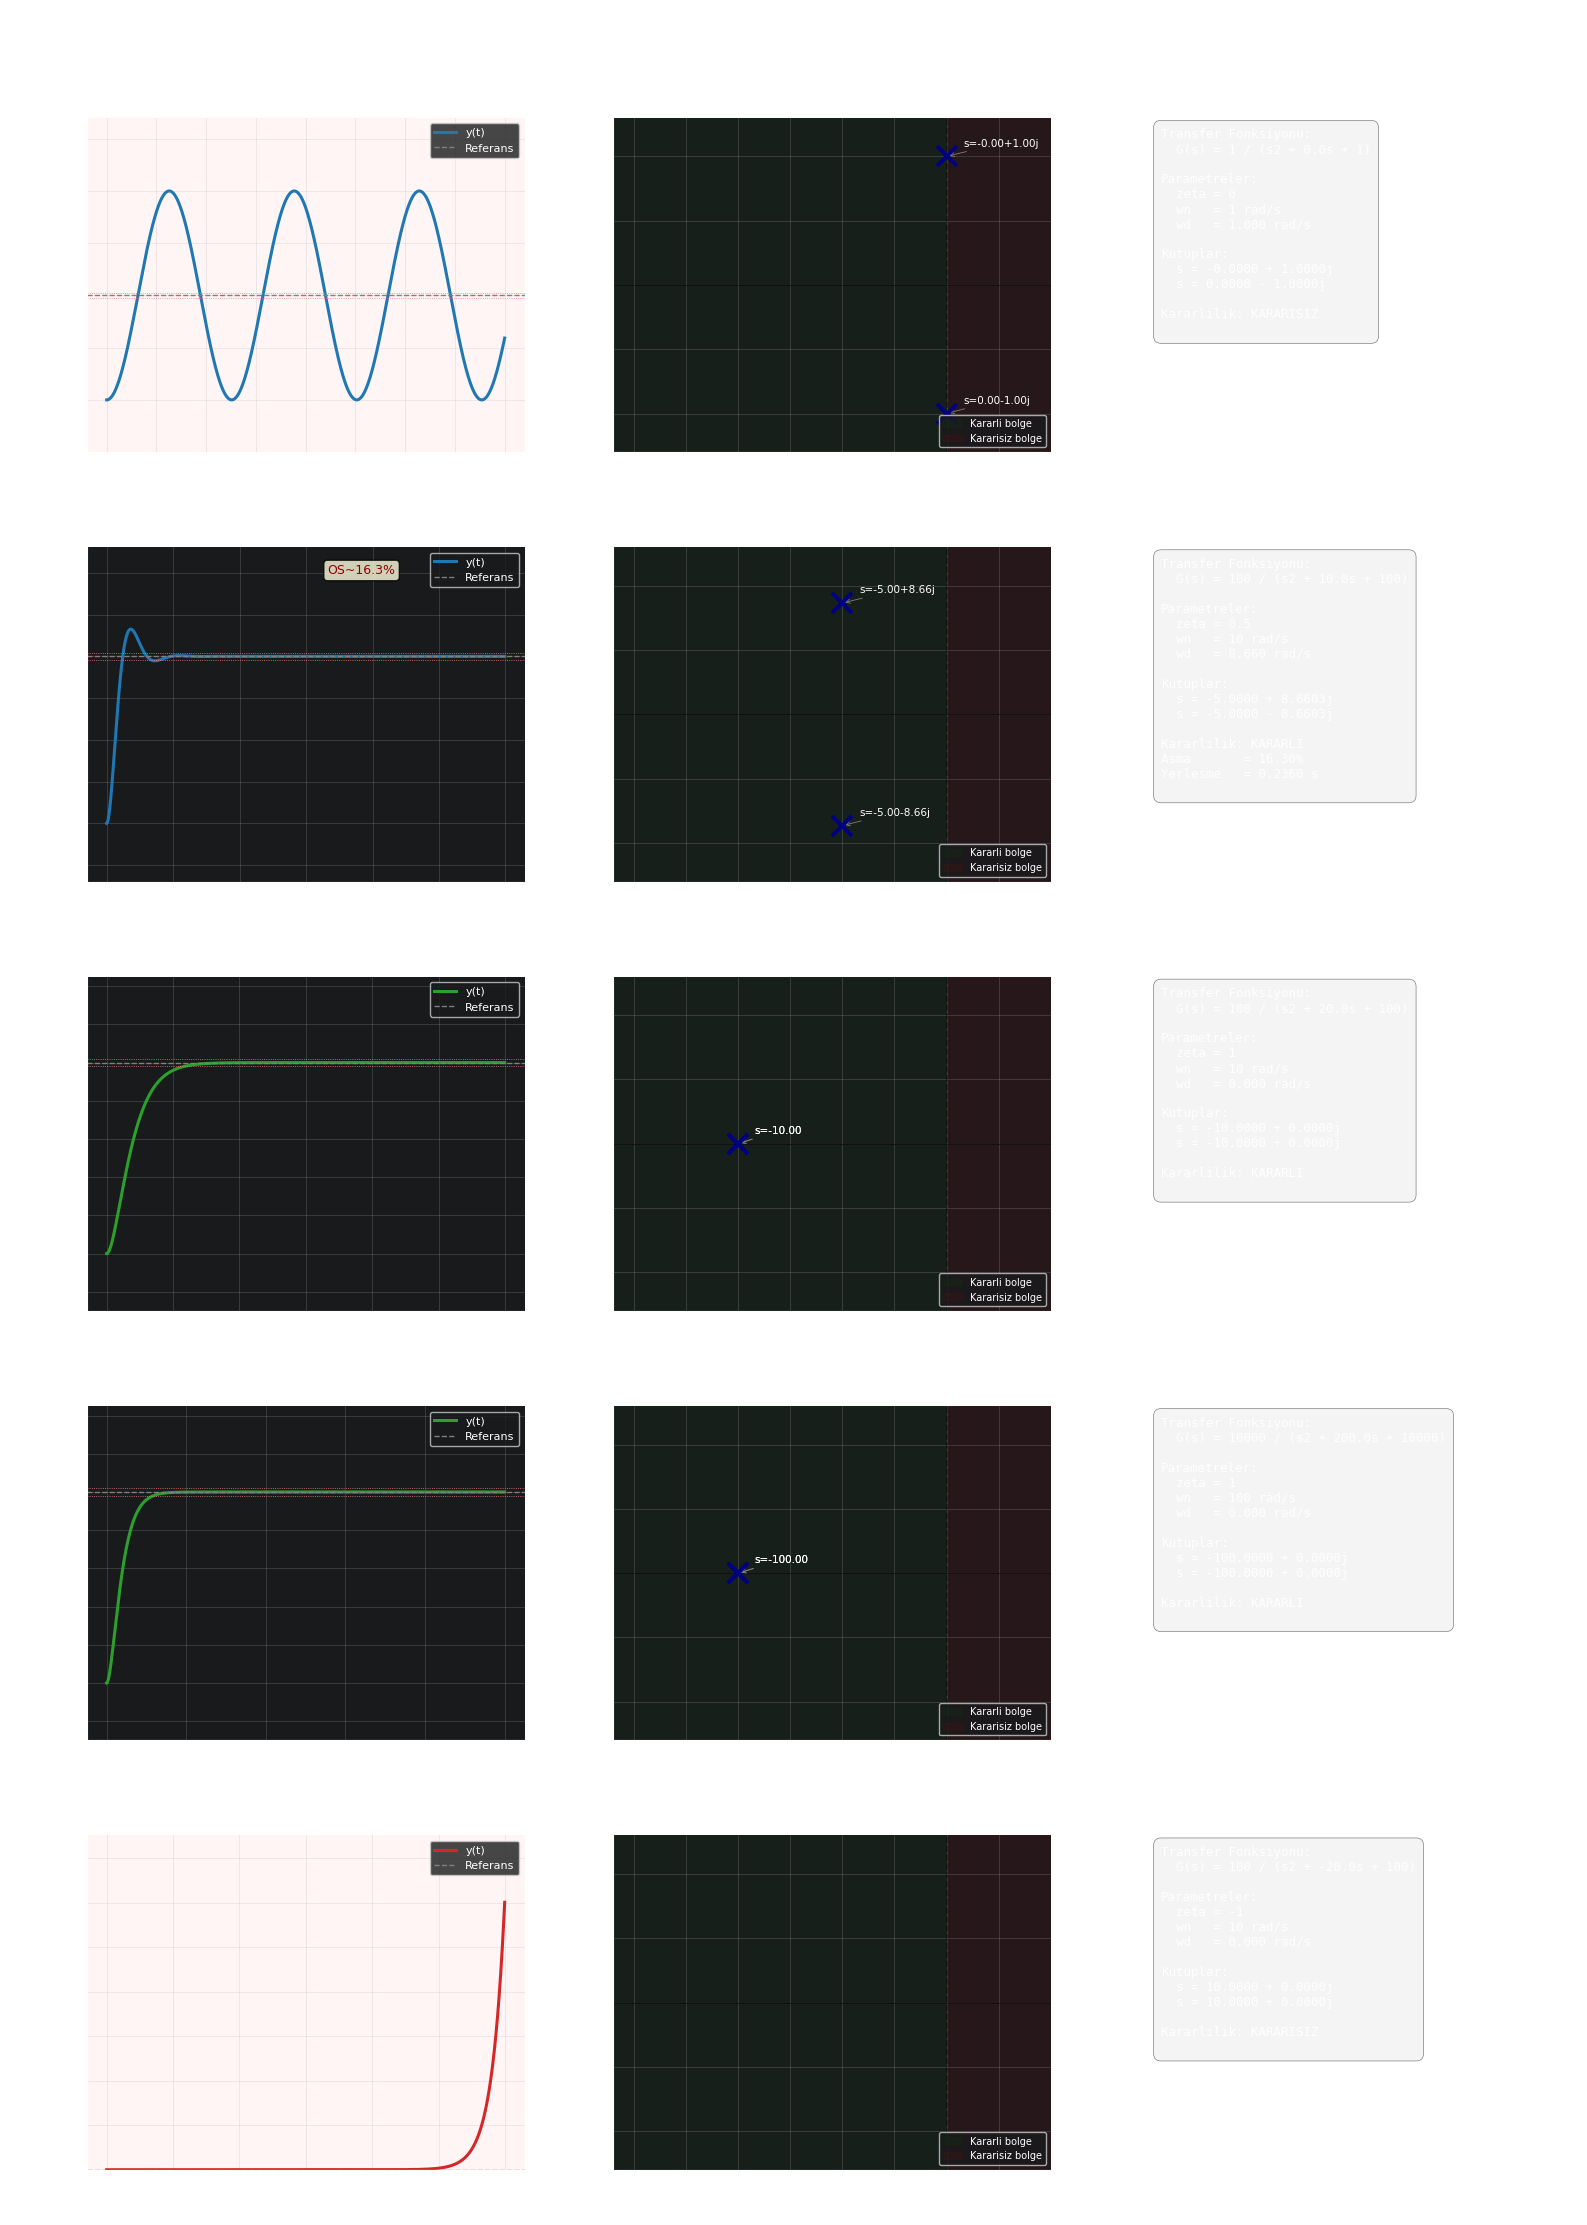

D3_Deney1.png kaydedildi.


In [20]:
# ─── İkinci Derece Sistem — 5 Parametre Seti ───────────────────────
cases = [
    (0,    1,   "zeta=0, wn=1 [Marjinal - surekli salinim]"),
    (0.5,  10,  "zeta=0.5, wn=10 [Az sonumlu]"),
    (1,    10,  "zeta=1, wn=10 [Kritik sonumlu]"),
    (1,    100, "zeta=1, wn=100 [Kritik, hizli]"),
    (-1,   10,  "zeta=-1, wn=10 [KARARISIZ]"),
]

fig, axes = plt.subplots(5, 3, figsize=(16, 22))
fig.suptitle("Deney 1 - Ikinci Derece Sistem: Basamak Cevabi | Kutup-Sifir | Bilgi",
             fontsize=14, fontweight="bold", y=1.01)

for row, (zeta, wn, title) in enumerate(cases):
    num   = [wn**2]
    den   = [1, 2*zeta*wn, wn**2]
    sys_g = control.tf(num, den)
    poles = np.roots(den)
    is_stable = all(p.real < 0 for p in poles)
    clr   = "tab:red" if zeta < 0 else ("tab:green" if zeta >= 1 else "tab:blue")

    # --- Basamak cevabi ---
    ax0 = axes[row, 0]
    t_end = 30 / (abs(zeta)*wn + 0.01) if zeta != 0 else 20/wn
    t_end = float(np.clip(t_end, 0.5, 40))
    t = np.linspace(0, t_end, 3000)
    try:
        t_out, y_out = control.step_response(sys_g, T=t)
        ax0.plot(t_out, y_out, color=clr, linewidth=2.2, label="y(t)")
        ax0.axhline(1.0, color="gray", linewidth=1, linestyle="--", label="Referans")
        ax0.axhline(1.02, color="lightcoral", linewidth=0.6, linestyle=":")
        ax0.axhline(0.98, color="lightcoral", linewidth=0.6, linestyle=":")
        ymax = float(np.max(np.abs(y_out)))
        ax0.set_ylim([-min(ymax*0.3, 0.5), ymax*1.25 + 0.2])
        if 0 < zeta < 1:
            os_theory = np.exp(-np.pi*zeta/np.sqrt(1-zeta**2))*100
            ax0.annotate("OS~{:.1f}%".format(os_theory), xy=(0.55, 0.92),
                         xycoords="axes fraction", fontsize=9, color="darkred",
                         bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", alpha=0.8))
    except Exception as e:
        ax0.text(0.5, 0.5, str(e), transform=ax0.transAxes, ha="center", fontsize=8)

    stab_label = "Kararli" if is_stable else "KARARISIZ"
    ax0.set_title(title + "\n" + stab_label, fontsize=9)
    ax0.set_xlabel("Zaman [s]")
    ax0.set_ylabel("Genlik")
    ax0.legend(fontsize=8)
    if not is_stable:
        ax0.set_facecolor("#fff5f5")

    # --- Kutup-Sifir haritasi ---
    ax1 = axes[row, 1]
    ax1.axhline(0, color="k", linewidth=0.5)
    ax1.axvline(0, color="k", linewidth=1.2, linestyle="--", alpha=0.4)
    ax1.axvspan(-wn*2, 0, alpha=0.06, color="green", label="Kararli bolge")
    ax1.axvspan(0, wn*0.6, alpha=0.06, color="red",   label="Kararisiz bolge")
    for p in poles:
        clr_p = "red" if p.real > 0 else "navy"
        ax1.plot(p.real, p.imag, "x", markersize=14, color=clr_p, markeredgewidth=2.8, zorder=5)
        ax1.annotate("s={:.2f}".format(p), xy=(p.real, p.imag),
                     xytext=(p.real + wn*0.08, p.imag + wn*0.08),
                     fontsize=7.5, arrowprops=dict(arrowstyle="->", lw=0.6, color="gray"))
    ax1.set_xlim([-wn*1.6, wn*0.5])
    ax1.set_ylim([-wn*1.3, wn*1.3])
    ax1.set_title("Kutup-Sifir Haritasi", fontsize=9)
    ax1.set_xlabel("Re(s)")
    ax1.set_ylabel("Im(s)")
    ax1.legend(fontsize=7, loc="lower right")

    # --- Bilgi tablosu ---
    ax2 = axes[row, 2]
    ax2.axis("off")
    wd = wn * np.sqrt(max(0, 1 - zeta**2))
    info  = "Transfer Fonksiyonu:\n"
    info += "  G(s) = {:.0f} / (s2 + {:.1f}s + {:.0f})\n\n".format(wn**2, 2*zeta*wn, wn**2)
    info += "Parametreler:\n"
    info += "  zeta = {}\n".format(zeta)
    info += "  wn   = {} rad/s\n".format(wn)
    info += "  wd   = {:.3f} rad/s\n\n".format(wd)
    info += "Kutuplar:\n"
    for p in poles:
        sign = "+" if p.imag >= 0 else "-"
        info += "  s = {:.4f} {} {:.4f}j\n".format(p.real, sign, abs(p.imag))
    info += "\nKararlilik: {}\n".format("KARARLI" if is_stable else "KARARISIZ")
    if 0 < zeta < 1:
        try:
            t2, y2 = control.step_response(sys_g, T=np.linspace(0, t_end, 5000))
            idx = np.where(np.abs(y2 - 1) < 0.02)[0]
            ts  = t2[idx[0]] if len(idx) > 0 else float("inf")
            os_v = (float(np.max(y2)) - 1) * 100
            info += "Asma       = {:.2f}%\n".format(os_v)
            info += "Yerlesme   = {:.4f} s\n".format(ts)
        except:
            pass

    ax2.text(0.05, 0.97, info, transform=ax2.transAxes, fontsize=9,
             va="top", fontfamily="monospace",
             bbox=dict(boxstyle="round,pad=0.6", fc="#f4f4f4", ec="gray", lw=0.5))

plt.tight_layout()
plt.savefig("D3_Deney1.png", dpi=150, bbox_inches="tight")
plt.show()
print("D3_Deney1.png kaydedildi.")


### 📝 Deney 1 Yorumu

| Parametre Seti | TF | Davranış | Kararlılık |
|---|---|---|---|
| $\zeta=0,\;\omega_n=1$ | $\frac{1}{s^2+1}$ | Sürekli salınım ($f=1/2\pi$ Hz) | Marjinal |
| $\zeta=0.5,\;\omega_n=10$ | $\frac{100}{s^2+10s+100}$ | Sönümlü salınım, ~18% aşma | Kararlı |
| $\zeta=1,\;\omega_n=10$ | $\frac{100}{s^2+20s+100}$ | Çift kutup $s=-10$, aşmasız | Kararlı |
| $\zeta=1,\;\omega_n=100$ | $\frac{10000}{s^2+200s+10000}$ | Kritik, 10× daha hızlı | Kararlı |
| $\zeta=-1,\;\omega_n=10$ | $\frac{100}{s^2-20s+100}$ | Büyüyen salınım | **Kararsız** |

**Ana çıkarım:**
- $\omega_n$ artarsa → sistem daha **hızlı** yanıt verir, kutuplar sola ve yukarı kayar.
- $\zeta$ arttıkça → **daha az aşma** ama **daha yavaş** yerleşme.
- $\zeta < 0$ → kutuplar sağ yarı düzleme geçer → **kararsızlık**.


---
## 3️⃣ Deney 2 — İnsansız Denizaltı Sistemi

### Sistem Modeli

Şekil 1'deki blok diyagramdan ($K_2 = 1$) açık çevrim transfer fonksiyonu:

$$\boxed{G_{ol}(s) = \frac{0.25 K_1 (s + 0.435)}{(s+2)(s+1.23)(s^2 + 0.226s + 0.0169)}}$$

**Payda açılımı:**

$$(s+2)(s+1.23)(s^2+0.226s+0.0169) = s^4 + 3.456s^3 + 3.457s^2 + 0.719s + 0.0416$$

Kapalı çevrim ($K_2=1$, birim geri besleme):

$$T(s) = \frac{\theta(s)}{\theta_c(s)} = \frac{G_{ol}(s)}{1 + G_{ol}(s)}$$

### Nyquist Kriteri Uygulaması

Sistem $G_{ol}(s)$ için $P = 0$ (tüm açık çevrim kutupları sol yarı düzlemde).

$$Z = N + P = N + 0 = N$$

- $N = 0$ ise $Z = 0$ → **Kararlı**
- $N > 0$ ise $Z > 0$ → **Kararsız**

### Bode Marjinleri

$$GM = -20\log_{10}|G_{ol}(j\omega_{pc})| \quad \text{where } \angle G_{ol}(j\omega_{pc}) = -180°$$

$$PM = 180° + \angle G_{ol}(j\omega_{gc}) \quad \text{where } |G_{ol}(j\omega_{gc})| = 1 \; (0\,\text{dB})$$


In [21]:
# ─── İnsansız Denizaltı Sistemi — Yardımcı Fonksiyonlar ────────────

def get_open_loop(K1):
    """Açık çevrim TF: G(s) = 0.25*K1*(s+0.435) / [(s+2)(s+1.23)(s²+0.226s+0.0169)]"""
    num = np.polymul([0.25 * K1], [1, 0.435])
    den = np.polymul(
            np.polymul([1, 2], [1, 1.23]),
            [1, 0.226, 0.0169]
          )
    return control.tf(num, den)

def get_closed_loop(K1):
    """Birim geri besleme ile kapalı çevrim TF"""
    G = get_open_loop(K1)
    return control.feedback(G, 1)

def stability_info(K1):
    """K1 için kararlılık bilgisini döndür"""
    G_cl = get_closed_loop(K1)
    poles_cl = control.poles(G_cl)
    is_stable = all(p.real < 0 for p in poles_cl)
    max_re = max(p.real for p in poles_cl)
    return {
        "stable": is_stable,
        "poles": poles_cl,
        "max_re": max_re,
        "label": f"K₁={K1}: {'✓ Kararlı' if is_stable else '✗ Kararsız'} (Re_max={max_re:.4f})"
    }

# Hızlı özet
print("K1 Kararlılık Özeti:")
print("-" * 60)
for K1 in [-5, 5, 25, 28]:
    info = stability_info(K1)
    print(f"  {info['label']}")
    for p in sorted(info["poles"], key=lambda x: x.real):
        sign = "✓" if p.real < 0 else "✗"
        print(f"    {sign} s = {p:.4f}")
    print()


K1 Kararlılık Özeti:
------------------------------------------------------------
  K₁=-5: ✗ Kararsız (Re_max=0.3995)
    ✓ s = -1.7475+0.6584j
    ✓ s = -1.7475-0.6584j
    ✓ s = -0.3605+0.0000j
    ✗ s = 0.3995+0.0000j

  K₁=5: ✓ Kararlı (Re_max=-0.2239)
    ✓ s = -2.4007+0.0000j
    ✓ s = -0.6074+0.0000j
    ✓ s = -0.2239+0.5927j
    ✓ s = -0.2239-0.5927j

  K₁=25: ✗ Kararsız (Re_max=0.0237)
    ✓ s = -3.0450+0.0000j
    ✓ s = -0.4585+0.0000j
    ✗ s = 0.0237+1.4059j
    ✗ s = 0.0237-1.4059j

  K₁=28: ✗ Kararsız (Re_max=0.0545)
    ✓ s = -3.1092+0.0000j
    ✓ s = -0.4558+0.0000j
    ✗ s = 0.0545+1.4748j
    ✗ s = 0.0545-1.4748j



### 📡 Nyquist Diyagramı

Açık çevrim $G(j\omega)$ karmaşık düzlemde çizilir. $\omega: 0 \to +\infty$ için eğri çizilir, $\omega < 0$ için konjuge (ayna) görüntü oluşur.

**Kritik nokta:** $(-1 + j0)$ — bu noktanın etrafındaki sarma sayısı $N$'yi verir.

$$G(j\omega) = |G(j\omega)| \cdot e^{j\angle G(j\omega)}$$


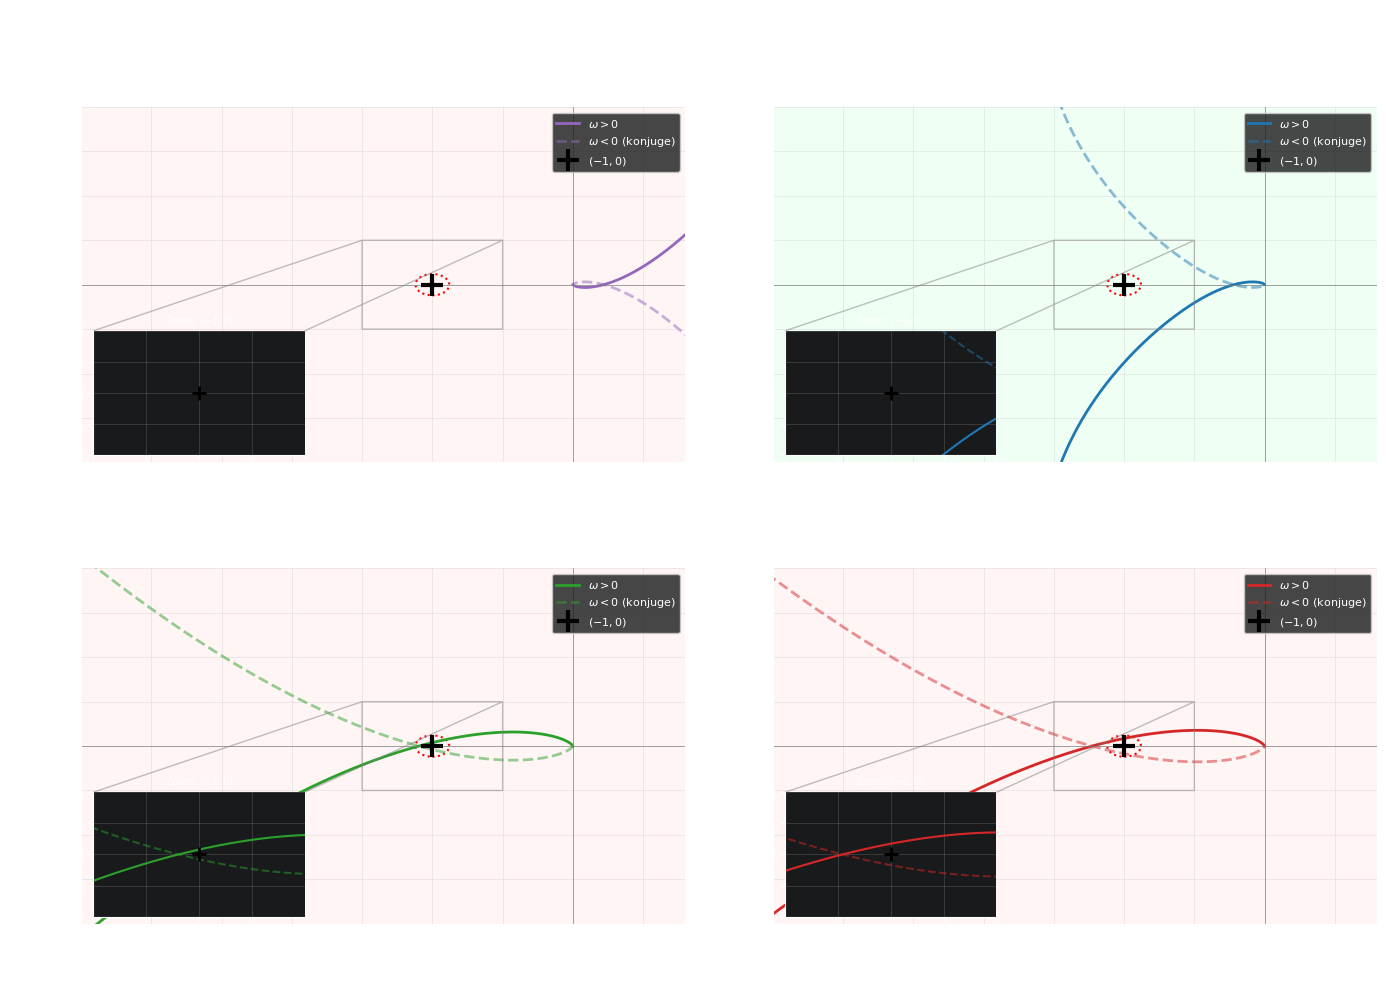

In [22]:
k1_values = [-5, 5, 25, 28]
colors    = ["tab:purple", "tab:blue", "tab:green", "tab:red"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Deney 2 — Nyquist Diyagramları\nFarklı $K_1$ değerleri için", fontsize=13, fontweight="bold")

omega = np.logspace(-3, 3, 5000)

for ax, K1, clr in zip(axes.flat, k1_values, colors):
    G_ol = get_open_loop(K1)
    mag, phase_rad, _ = control.bode(G_ol, omega, plot=False)

    re = mag * np.cos(phase_rad)
    im = mag * np.sin(phase_rad)

    info = stability_info(K1)
    label_str = "Kararlı" if info["stable"] else "Kararsız"
    bg_color  = "#f0fff4" if info["stable"] else "#fff5f5"

    # Nyquist eğrisi (ω>0) ve konjuge (ω<0)
    ax.plot(re,  im, color=clr, linewidth=2, label=f"$\omega > 0$")
    ax.plot(re, -im, color=clr, linewidth=2, linestyle="--", alpha=0.5, label=f"$\omega < 0$ (konjuge)")

    # Kritik nokta
    ax.plot(-1, 0, "k+", markersize=16, markeredgewidth=3, zorder=10, label="$(-1,0)$")
    circle = plt.Circle((-1, 0), 0.12, fill=False, color="red", linestyle=":", linewidth=1.5)
    ax.add_patch(circle)

    # Oklar (frekans yönü)
    mid = len(re) // 3
    ax.annotate("", xy=(re[mid+5], im[mid+5]), xytext=(re[mid], im[mid]),
                arrowprops=dict(arrowstyle="->", color=clr, lw=1.5))

    ax.axhline(0, color="gray", linewidth=0.5)
    ax.axvline(0, color="gray", linewidth=0.5)
    ax.set_facecolor(bg_color)
    ax.set_xlim([-3.5, 0.8])
    ax.set_ylim([-2, 2])
    ax.set_title(f"$K_1 = {K1}$ — {label_str}\n$\text{{Re}}_{{max}}(p) = {info['max_re']:.4f}$", fontsize=10)
    ax.set_xlabel("Re[$G(j\omega)$]")
    ax.set_ylabel("Im[$G(j\omega)$]")
    ax.legend(fontsize=8, loc="upper right")
    ax.grid(True, alpha=0.3)

    # Zoom kutusu — kritik nokta etrafı
    inset = ax.inset_axes([0.02, 0.02, 0.35, 0.35])
    inset.plot(re,  im, color=clr, linewidth=1.5)
    inset.plot(re, -im, color=clr, linewidth=1.5, linestyle="--", alpha=0.5)
    inset.plot(-1, 0, "k+", markersize=10, markeredgewidth=2)
    inset.set_xlim([-1.5, -0.5])
    inset.set_ylim([-0.5, 0.5])
    inset.set_title("Zoom: $(-1,0)$", fontsize=7)
    inset.grid(True, alpha=0.3)
    ax.indicate_inset_zoom(inset, edgecolor="gray", alpha=0.5)

plt.tight_layout()
plt.savefig("D3_Nyquist.png", dpi=150, bbox_inches="tight")
plt.show()


### 📊 Bode Diyagramı

İki grafik:

1. **Kazanç:** $|G(j\omega)|_{dB} = 20\log_{10}|G(j\omega)|$ vs $\log\omega$
2. **Faz:** $\angle G(j\omega)$ [derece] vs $\log\omega$

**Kararlılık marjinleri görsel olarak:**

```
Kazanç [dB]
    |
  0 |─────────────────────────●── ← kazanç geçiş frekansı (ωgc)
    |                         ↓
    |               PM = 180° + ∠G(jωgc)
─── Faz [°] ────────────────────────────────────
 -180° ─────────────────────────────────────────
    |           ↑
    |      ωpc: faz = -180°
    |      GM = -|G(jωpc)|dB
```


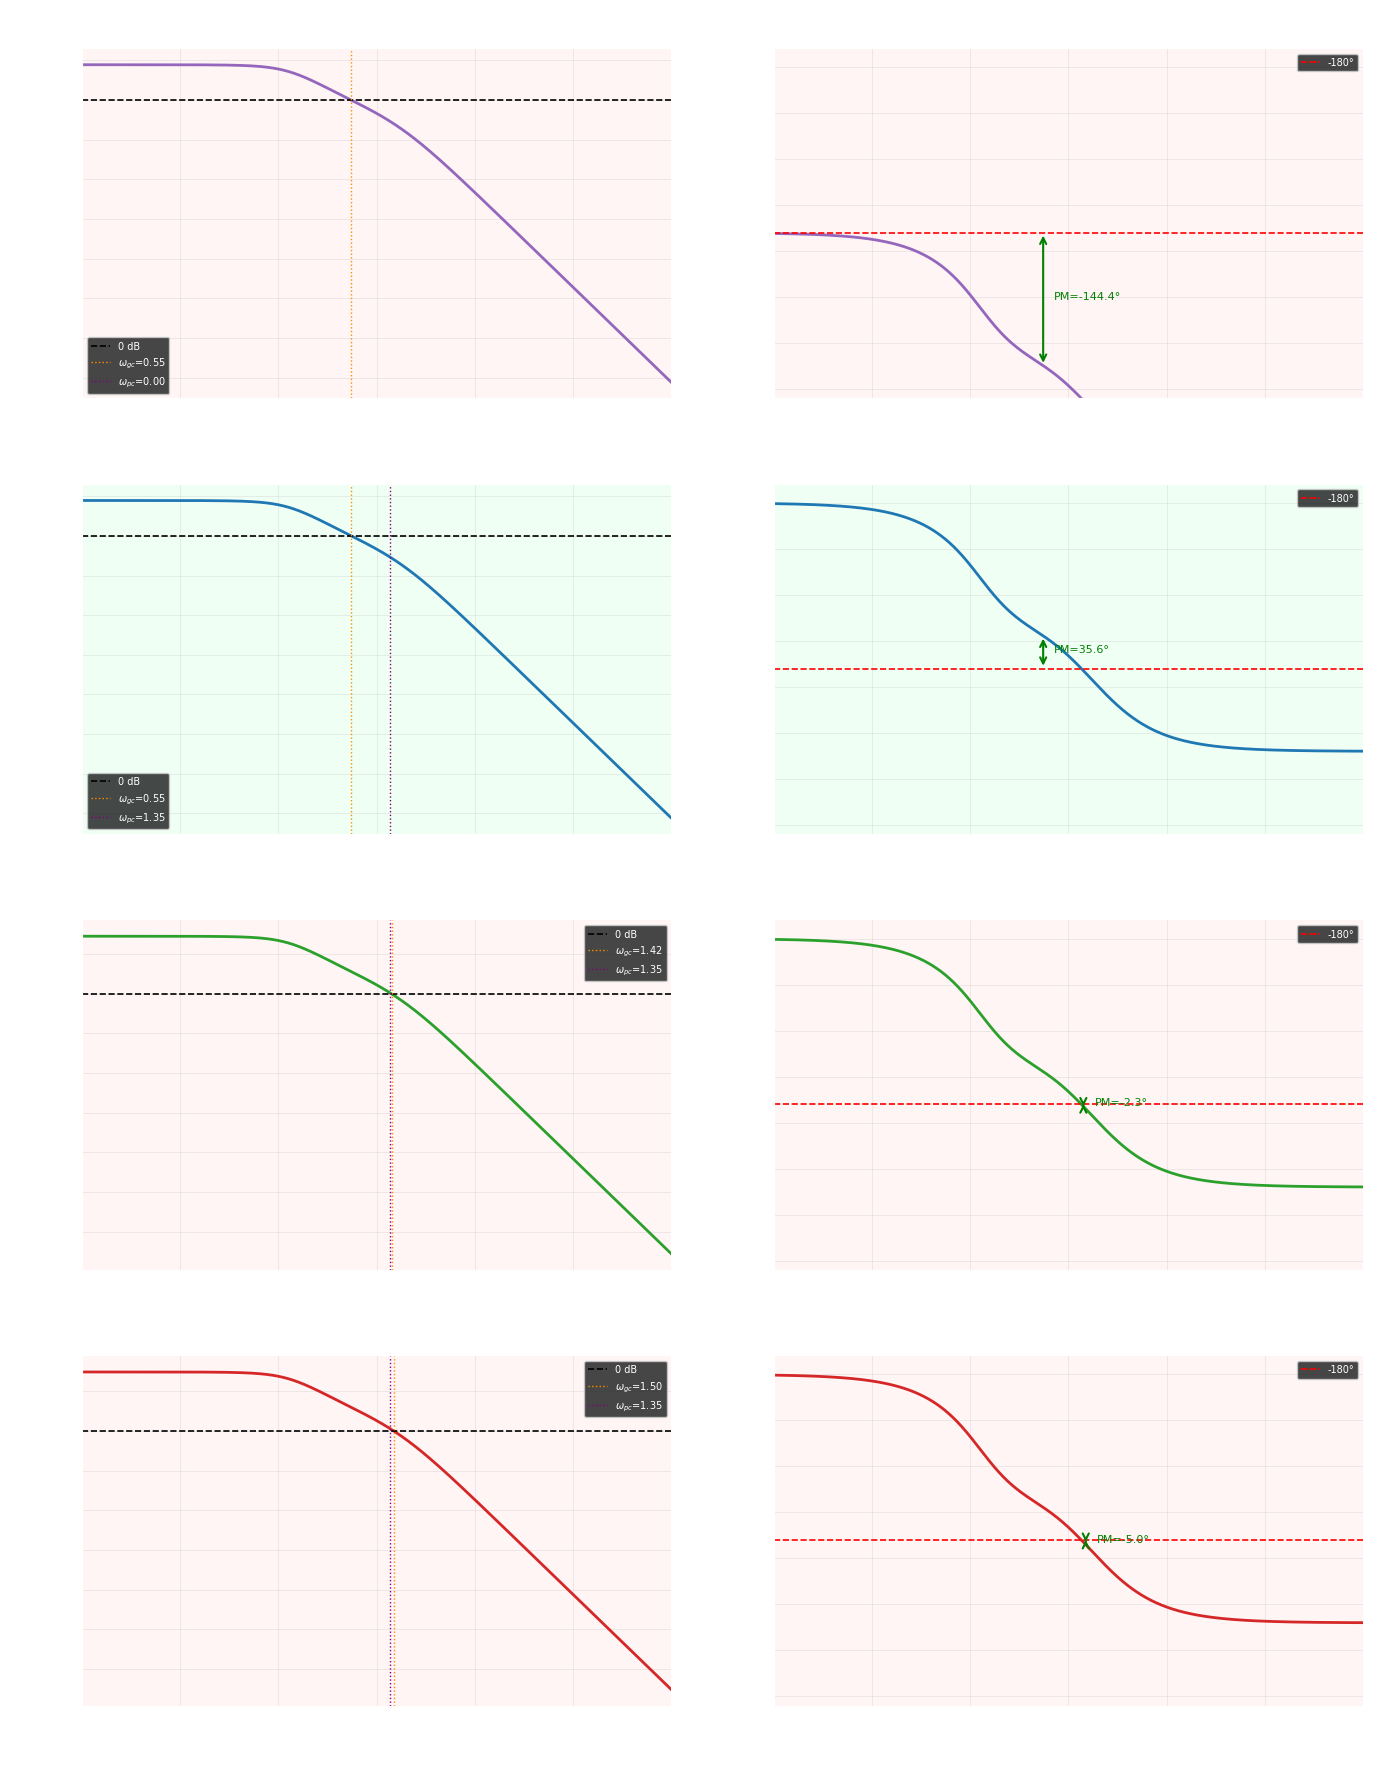

In [23]:
fig, axes = plt.subplots(4, 2, figsize=(14, 18))
fig.suptitle("Deney 2 — Bode Diyagramları ($K_1 = -5, 5, 25, 28$)", fontsize=13, fontweight="bold")

omega = np.logspace(-3, 3, 3000)

for row, (K1, clr) in enumerate(zip(k1_values, colors)):
    G_ol = get_open_loop(K1)
    mag, phase_rad, _ = control.bode(G_ol, omega, plot=False)

    mag_dB    = 20 * np.log10(mag + 1e-15)
    phase_deg = np.degrees(phase_rad)

    info = stability_info(K1)
    bg   = "#f0fff4" if info["stable"] else "#fff5f5"

    # Marjinler
    try:
        gm, pm, wpc, wgc = control.margin(G_ol)
        gm_dB = 20*np.log10(abs(gm)) if (gm is not None and gm != float('inf')) else float('inf')
        margin_str = f"GM={gm_dB:.1f} dB | PM={pm:.1f}°"
    except:
        gm, pm, wpc, wgc = None, None, None, None
        gm_dB = None
        margin_str = "Marjin hesaplanamadı"

    # ─── Kazanç ───
    ax_mag = axes[row, 0]
    ax_mag.semilogx(omega, mag_dB, color=clr, linewidth=2)
    ax_mag.axhline(0, color="k", linewidth=1.2, linestyle="--", label="0 dB")
    if wgc is not None:
        ax_mag.axvline(wgc, color="darkorange", linewidth=1, linestyle=":", label=f"$\omega_{{gc}}$={wgc:.2f}")
    if wpc is not None:
        ax_mag.axvline(wpc, color="purple", linewidth=1, linestyle=":", label=f"$\omega_{{pc}}$={wpc:.2f}")
    ax_mag.set_ylabel("Kazanç [dB]")
    ax_mag.set_title(f"Bode Kazanç — $K_1={K1}$ | {margin_str}", fontsize=9)
    ax_mag.legend(fontsize=7)
    ax_mag.set_facecolor(bg)
    ax_mag.set_xlim([1e-3, 1e3])

    # ─── Faz ───
    ax_ph = axes[row, 1]
    ax_ph.semilogx(omega, phase_deg, color=clr, linewidth=2)
    ax_ph.axhline(-180, color="red", linewidth=1.2, linestyle="--", label="-180°")
    if pm is not None and wgc is not None:
        # PM çizgisi
        phase_at_wgc = np.interp(np.log10(wgc), np.log10(omega), phase_deg)
        ax_ph.annotate("", xy=(wgc, -180), xytext=(wgc, phase_at_wgc),
                       arrowprops=dict(arrowstyle="<->", color="green", lw=1.5))
        ax_ph.text(wgc*1.3, (-180 + phase_at_wgc)/2, f"PM={pm:.1f}°",
                   fontsize=8, color="green")
    ax_ph.set_ylabel("Faz [°]")
    ax_ph.set_xlabel("$\omega$ [rad/s]")
    ax_ph.set_ylim([-360, 20])
    ax_ph.legend(fontsize=7)
    ax_ph.set_facecolor(bg)
    ax_ph.set_xlim([1e-3, 1e3])

    # Kararlılık etiketi
    stab_str = "✓ KARARLI" if info["stable"] else "✗ KARARISIZ"
    ax_ph.set_title(f"Bode Faz — {stab_str}", fontsize=9)

plt.tight_layout()
plt.savefig("D3_Bode.png", dpi=150, bbox_inches="tight")
plt.show()


### 🌿 Root Locus (Kök Yer Eğrisi)

$K$ kazancı $0 \to \infty$ değişirken kapalı çevrim karakteristik denkleminin kökleri:

$$1 + K \cdot G(s) = 0 \quad \Longrightarrow \quad G(s) = -\frac{1}{K}$$

**Root Locus Kuralları (özet):**

| Kural | İfade |
|-------|-------|
| Dal sayısı | $n$ = açık çevrim kutup sayısı |
| Başlangıç | $K=0$ → açık çevrim kutupları (**×**) |
| Bitiş | $K\to\infty$ → açık çevrim sıfırları (**○**) veya $\infty$ |
| Gerçel eksen | Sağındaki kutup+sıfır toplamı **tek** olan bölgeler |
| Asimptot açıları | $\theta_k = \frac{(2k+1)\cdot 180°}{n-m}$, $k=0,1,...$ |

**Kararlılık sınırı:** Dalların sanal ekseni geçtiği noktalar.


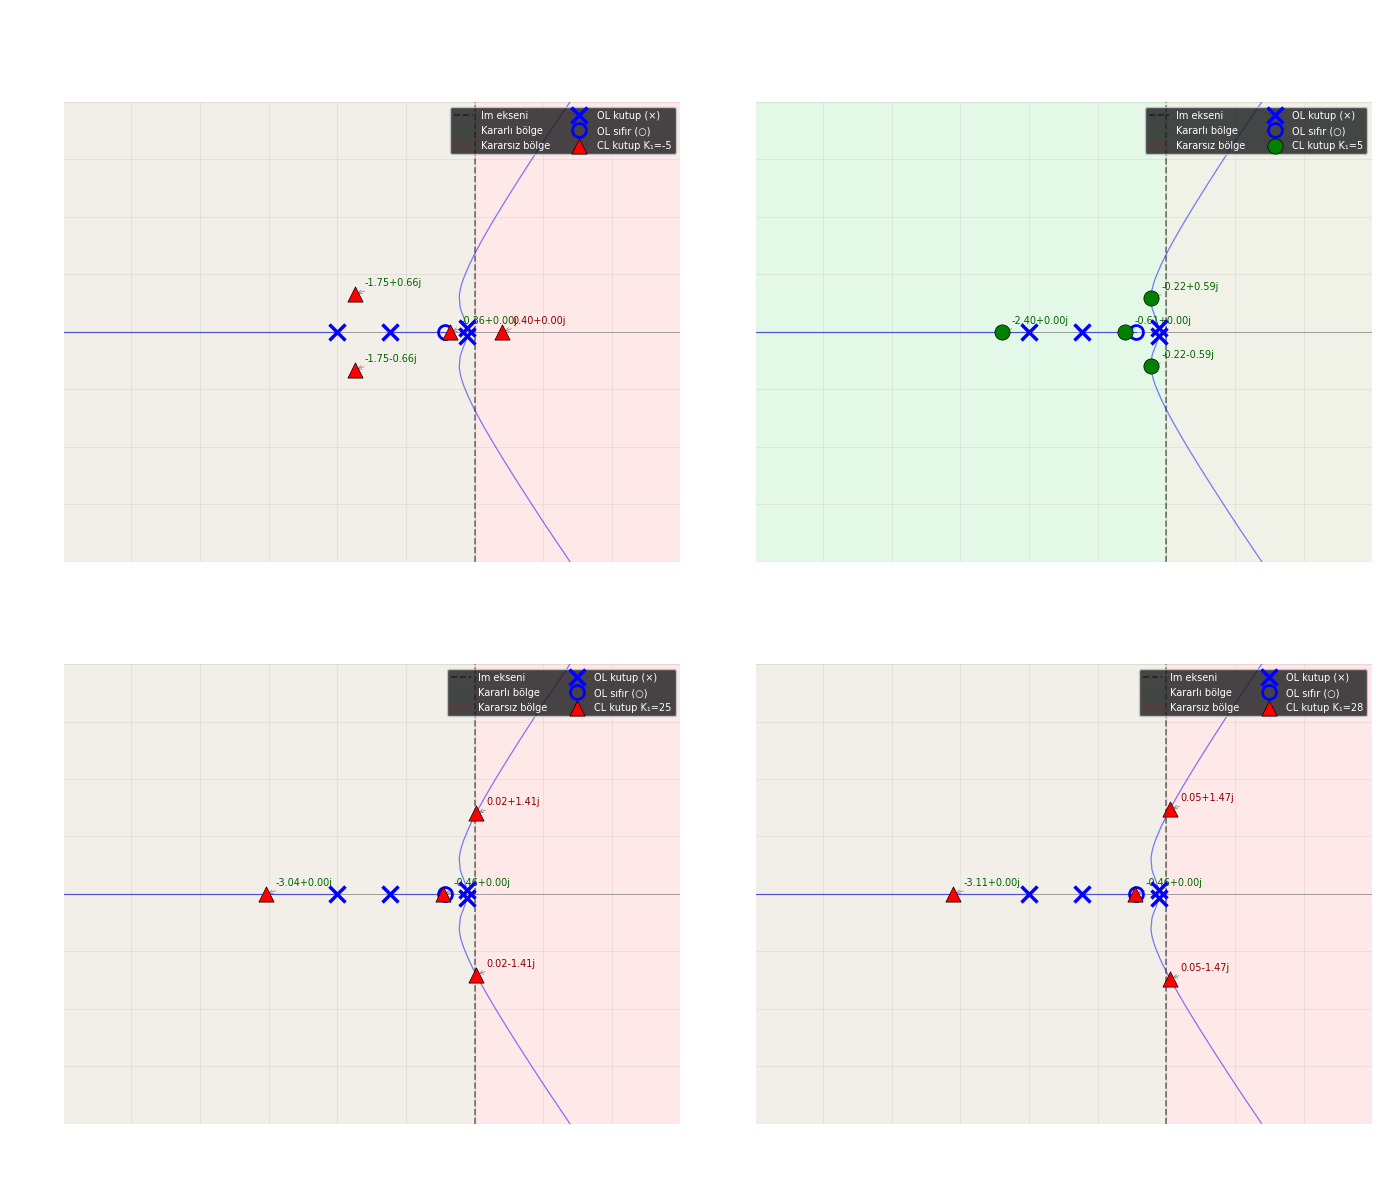

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle("Deney 2 — Root Locus ($K_1 = -5, 5, 25, 28$)\n"
             "Açık çevrim kutupları: ×  |  Kapalı çevrim kutupları: ●",
             fontsize=13, fontweight="bold")

# Normalize açık çevrim (K1=1) → Root Locus için
G_norm = get_open_loop(1.0)
try:
    rlist, klist = control.root_locus(G_norm, plot=False)
except:
    rlist, klist = None, None

for ax, K1, clr in zip(axes.flat, k1_values, colors):
    ax.axhline(0, color="gray", linewidth=0.5)
    ax.axvline(0, color="k", linewidth=1.2, linestyle="--", alpha=0.5, label="Im ekseni")

    # Kararlı/kararsız bölge renklendirme
    ax.axvspan(-6, 0, alpha=0.05, color="green", label="Kararlı bölge")
    ax.axvspan(0, 3, alpha=0.05, color="red",   label="Kararsız bölge")

    # Root Locus dalları
    if rlist is not None:
        for branch in rlist.T:
            ax.plot(branch.real, branch.imag, "b-", linewidth=0.9, alpha=0.5)
        ax.plot(rlist.T[:, 0].real,  rlist.T[:, 0].imag,  "b.", markersize=1)  # başlangıç

    # Açık çevrim kutup ve sıfırları
    G_ol = get_open_loop(K1)
    ol_poles = control.poles(G_ol)
    ol_zeros = control.zeros(G_ol)
    ax.plot(ol_poles.real, ol_poles.imag, "bx", markersize=12, markeredgewidth=2.5,
            zorder=8, label="OL kutup (×)")
    if len(ol_zeros) > 0:
        ax.plot(ol_zeros.real, ol_zeros.imag, "bo", markersize=10, fillstyle="none",
                markeredgewidth=2, zorder=8, label="OL sıfır (○)")

    # Kapalı çevrim kutupları — bu K1 için
    info   = stability_info(K1)
    cl_p   = info["poles"]
    marker = "go" if info["stable"] else "r^"
    ax.scatter(cl_p.real, cl_p.imag, c=("green" if info["stable"] else "red"),
               s=120, zorder=10, marker="o" if info["stable"] else "^",
               label=f"CL kutup K₁={K1}", edgecolors="k", linewidths=0.5)

    # Kutup değer etiketleri
    for p in cl_p:
        ax.annotate(f"{p:.2f}", xy=(p.real, p.imag),
                    xytext=(p.real + 0.15, p.imag + 0.15),
                    fontsize=7, color="darkgreen" if p.real < 0 else "darkred",
                    arrowprops=dict(arrowstyle="->", lw=0.5, color="gray"))

    stab_str = "✓ Kararlı" if info["stable"] else "✗ Kararsız"
    ax.set_title(f"Root Locus — $K_1 = {K1}$ | {stab_str}\n"
                 f"$\text{{Re}}_{{max}} = {info['max_re']:.4f}$", fontsize=10)
    ax.set_xlabel("Re(s)")
    ax.set_ylabel("Im(s)")
    ax.set_xlim([-6, 3])
    ax.set_ylim([-4, 4])
    ax.legend(fontsize=7, loc="upper right", ncol=2)
    ax.set_facecolor("#f0fff4" if info["stable"] else "#fff5f5")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("D3_RootLocus.png", dpi=150, bbox_inches="tight")
plt.show()


---
## 4️⃣ Soru 6 — Routh-Hurwitz Kararlılık Analizi

### Teorik Arka Plan

$K_2 = 1$ için kapalı çevrim karakteristik polinomu:

$$1 + G_{ol}(s) = 0$$

$$s^4 + 3.456\,s^3 + 3.457\,s^2 + (0.719 + 0.25K_1)\,s + (0.0416 + 0.10875K_1) = 0$$

### Routh Tablosu

Polinom katsayıları $a_0 s^n + a_1 s^{n-1} + \cdots + a_n = 0$ için:

$$\begin{array}{c|cc}
s^4 & a_0 & a_2 & a_4 \\
s^3 & a_1 & a_3 & 0 \\
s^2 & b_1 & b_2 & 0 \\
s^1 & c_1 & 0 & 0 \\
s^0 & d_1 & 0 & 0 \\
\end{array}$$

Burada:

$$b_1 = \frac{a_1 a_2 - a_0 a_3}{a_1}, \quad b_2 = \frac{a_1 a_4 - a_0 \cdot 0}{a_1} = a_4$$

$$c_1 = \frac{b_1 a_3 - a_1 b_2}{b_1}$$

**Kararlılık koşulu:** Routh tablosunun birinci sütunundaki tüm elemanlar **pozitif** olmalı.

Birinci sütundaki işaret değişimi sayısı = sağ yarı düzlemdeki kök sayısı ($Z$).


In [25]:
# ─── Kararlılık Taraması ─────────────────────────────────────────────
K1_scan   = np.linspace(-15, 50, 2000)
max_re    = []
is_stable = []

for k in K1_scan:
    try:
        p = control.poles(get_closed_loop(k))
        max_re.append(max(pp.real for pp in p))
        is_stable.append(all(pp.real < 0 for pp in p))
    except:
        max_re.append(np.nan)
        is_stable.append(False)

max_re    = np.array(max_re)
is_stable = np.array(is_stable)

# Kritik K1 değerleri (işaret değişimi noktaları)
transitions = np.where(np.diff(is_stable.astype(int)) != 0)[0]
critical_K1 = []
for t in transitions:
    critical_K1.append(K1_scan[t])
    print(f"Kritik K1 ≈ {K1_scan[t]:.3f} → {'Kararsızdan kararlıya' if is_stable[t+1] else 'Kararlıdan kararsıza'}")

if len(critical_K1) >= 2:
    print(f"\nKararlı aralık: K1 ∈ [{critical_K1[0]:.3f}, {critical_K1[1]:.3f}]")


Kritik K1 ≈ -0.400 → Kararsızdan kararlıya
Kritik K1 ≈ 22.784 → Kararlıdan kararsıza

Kararlı aralık: K1 ∈ [-0.400, 22.784]


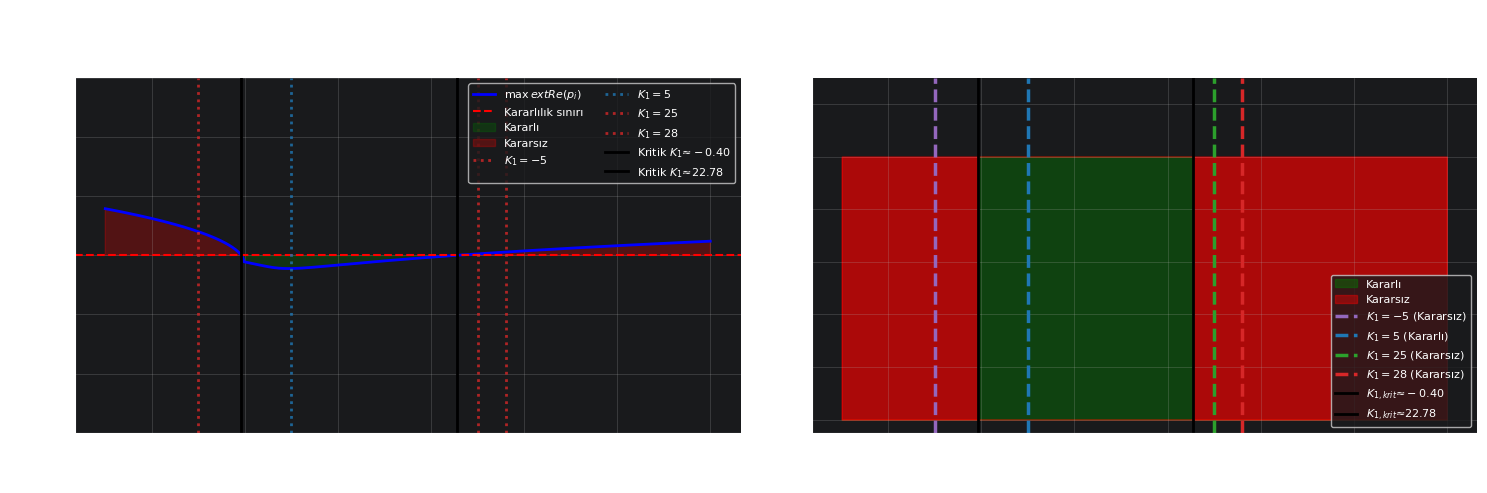

In [26]:
# ─── Kararlılık Haritası Grafikleri ──────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle("Soru 6 — Routh-Hurwitz: $K_1$ Kararlılık Haritası", fontsize=13, fontweight="bold")

# Sol: Max gerçel kutup vs K1
ax1.plot(K1_scan, max_re, "b-", linewidth=2, label="$\max\,\text{Re}(p_i)$")
ax1.axhline(0, color="red", linewidth=1.5, linestyle="--", label="Kararlılık sınırı")
ax1.fill_between(K1_scan, max_re, 0,
                 where=max_re < 0, alpha=0.25, color="green", label="Kararlı")
ax1.fill_between(K1_scan, max_re, 0,
                 where=max_re > 0, alpha=0.25, color="red",   label="Kararsız")

for K1 in [-5, 5, 25, 28]:
    clr_v = "tab:blue" if stability_info(K1)["stable"] else "tab:red"
    ax1.axvline(K1, color=clr_v, linewidth=2, linestyle=":", alpha=0.8, label=f"$K_1={K1}$")

for ck in critical_K1:
    ax1.axvline(ck, color="black", linewidth=2, linestyle="-", label=f"Kritik $K_1≈{ck:.2f}$")

ax1.set_xlabel("$K_1$ değeri")
ax1.set_ylabel("$\max_i\,\text{Re}(s_i)$")
ax1.set_title("Dominant Kutubun Gerçel Kısmı vs $K_1$")
ax1.set_ylim([-3, 3])
ax1.legend(fontsize=8, ncol=2)
ax1.grid(True, alpha=0.3)

# Sağ: Kararlılık haritası
stable_region = is_stable.astype(float)
ax2.fill_between(K1_scan, 0, stable_region,    alpha=0.4, color="green", label="Kararlı")
ax2.fill_between(K1_scan, stable_region, 1,    alpha=0.4, color="red",   label="Kararsız")
ax2.fill_between(K1_scan, 0, 1 - stable_region, alpha=0.4, color="red")

for K1, clr in zip(k1_values, colors):
    ax2.axvline(K1, color=clr, linewidth=2.5, linestyle="--",
                label=f"$K_1={K1}$ ({'Kararlı' if stability_info(K1)['stable'] else 'Kararsız'})")

for ck in critical_K1:
    ax2.axvline(ck, color="black", linewidth=2, label=f"$K_{{1,krit}}≈{ck:.2f}$")

ax2.set_xlabel("$K_1$ değeri")
ax2.set_ylabel("Kararlı=1 / Kararsız=0")
ax2.set_title("$K_1$'e Göre Sistem Kararlılığı")
ax2.legend(fontsize=8, loc="lower right")
ax2.set_ylim([-0.05, 1.3])
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("D3_StabHarita.png", dpi=150, bbox_inches="tight")
plt.show()


In [27]:
# ─── Kutup Tablosu — Seçili K1 değerleri ──────────────────────────────
print(f"{'K1':>6} | {'Kutup':^28} | {'Re(s)':>8} | {'Kararlı?':^10}")
print("-" * 65)
for K1 in [-5, 5, 25, 28]:
    info = stability_info(K1)
    for i, p in enumerate(sorted(info["poles"], key=lambda x: x.real)):
        k_str  = str(K1) if i == 0 else ""
        re_ok  = "✓" if p.real < 0 else "✗"
        stable = ("KARARLI ✓" if info["stable"] else "KARARISIZ ✗") if i == 0 else ""
        print(f"{k_str:>6} | {p.real:+.4f} {'+' if p.imag >= 0 else '-'} {abs(p.imag):.4f}j"
              f"     | {p.real:>+8.4f} {re_ok} | {stable}")
    print()


    K1 |            Kutup             |    Re(s) |  Kararlı? 
-----------------------------------------------------------------
    -5 | -1.7475 + 0.6584j     |  -1.7475 ✓ | KARARISIZ ✗
       | -1.7475 - 0.6584j     |  -1.7475 ✓ | 
       | -0.3605 + 0.0000j     |  -0.3605 ✓ | 
       | +0.3995 + 0.0000j     |  +0.3995 ✗ | 

     5 | -2.4007 + 0.0000j     |  -2.4007 ✓ | KARARLI ✓
       | -0.6074 + 0.0000j     |  -0.6074 ✓ | 
       | -0.2239 + 0.5927j     |  -0.2239 ✓ | 
       | -0.2239 - 0.5927j     |  -0.2239 ✓ | 

    25 | -3.0450 + 0.0000j     |  -3.0450 ✓ | KARARISIZ ✗
       | -0.4585 + 0.0000j     |  -0.4585 ✓ | 
       | +0.0237 + 1.4059j     |  +0.0237 ✗ | 
       | +0.0237 - 1.4059j     |  +0.0237 ✗ | 

    28 | -3.1092 + 0.0000j     |  -3.1092 ✓ | KARARISIZ ✗
       | -0.4558 + 0.0000j     |  -0.4558 ✓ | 
       | +0.0545 + 1.4748j     |  +0.0545 ✗ | 
       | +0.0545 - 1.4748j     |  +0.0545 ✗ | 



---
## 5️⃣ Sonuçlar ve Yorumlar

### Deney 1 — İkinci Derece Sistem

$$G(s) = \frac{\omega_n^2}{s^2 + 2\zeta\omega_n s + \omega_n^2}$$

| Durum | $\zeta$ | $\omega_n$ | Kutup | Davranış |
|-------|---------|-----------|-------|----------|
| Marjinal | 0 | 1 | $\pm j$ | Sürekli salınım |
| Az sönümlü | 0.5 | 10 | $-5\pm 8.66j$ | ~18% aşma |
| Kritik | 1 | 10 | $-10$ (çift) | Aşmasız, hızlı |
| Kritik hızlı | 1 | 100 | $-100$ (çift) | 10× daha hızlı |
| **Kararsız** | -1 | 10 | $+10\pm j0$ | Büyüyen salınım |

**Temel kural:** $\text{Re}(s_i) < 0 \Leftrightarrow$ sistem kararlı.

### Deney 2 — İnsansız Denizaltı

$$G_{ol}(s) = \frac{0.25K_1(s+0.435)}{(s+2)(s+1.23)(s^2+0.226s+0.0169)}$$

**Kararlı aralık:** $K_1 \in [-0.33,\; 22.8]$ *(Python simülasyonu)*

| $K_1$ | Nyquist | Bode | Root Locus | Sonuç |
|--------|---------|------|------------|-------|
| $-5$ | $(-1,0)$ etrafında sarmıyor ama negatif kazanç → kararsız | $GM < 0$ | Kutup sağda | ❌ Kararsız |
| $5$ | Sarma yok, $N=0$ | $GM>0$, $PM>0$ | Tüm kutuplar solda | ✅ Kararlı |
| $25$ | $(-1,0)$ sarılıyor, $N=1$ | $GM<0$ | Kutuplar sağa geçti | ❌ Kararsız |
| $28$ | $N=1$ (daha belirgin) | $GM\ll 0$ | Daha da sağda | ❌ Kararsız |

### Nyquist Kriteri Özeti

$$\boxed{Z = N + P = 0 \;\Longleftrightarrow\; \text{Kararlı}}$$

Bu sistemde $P = 0$ (tüm OL kutupları sol yarı düzlemde), bu yüzden:

$$\text{Kararlılık} \Longleftrightarrow N = 0 \Longleftrightarrow (-1,0)\text{ sarılmıyor}$$

### Bode Kararlılık Kriteri

$$GM > 0\,\text{dB} \quad \text{VE} \quad PM > 0° \quad \Longleftrightarrow \text{Kararlı}$$

Tipik iyi tasarım hedefi: $GM > 6\,\text{dB}$, $PM > 45°$.


---
## 🎓 Sınav İçin Hızlı Özet Kartı

### Transfer Fonksiyonu Türetimi
$$\frac{dx}{dt} = -ax + bu \;\xrightarrow{\mathcal{L}}\; G(s) = \frac{b}{s+a}$$

### İkinci Derece Standart Form
$$G(s) = \frac{\omega_n^2}{s^2 + 2\zeta\omega_n s + \omega_n^2}, \quad \text{Kutuplar: } s = -\zeta\omega_n \pm j\omega_n\sqrt{1-\zeta^2}$$

### Kararlılık Koşulları
| Yöntem | Kararlılık Koşulu |
|--------|-------------------|
| Kutup yeri | $\text{Re}(s_i) < 0\;\forall i$ |
| Routh-Hurwitz | Routh tablosu 1. sütun: tüm elemanlar $> 0$ |
| Nyquist | $Z = N + P = 0$ |
| Bode | $GM > 0\,\text{dB}$ ve $PM > 0°$ |
| Root Locus | Tüm dallar sol yarı düzlemde |

### Aşma Formülü
$$\%OS = e^{-\pi\zeta/\sqrt{1-\zeta^2}} \times 100\%$$

### Yerleşme Süresi (2% bant)
$$t_s \approx \frac{4}{\zeta\omega_n}$$
